<center>

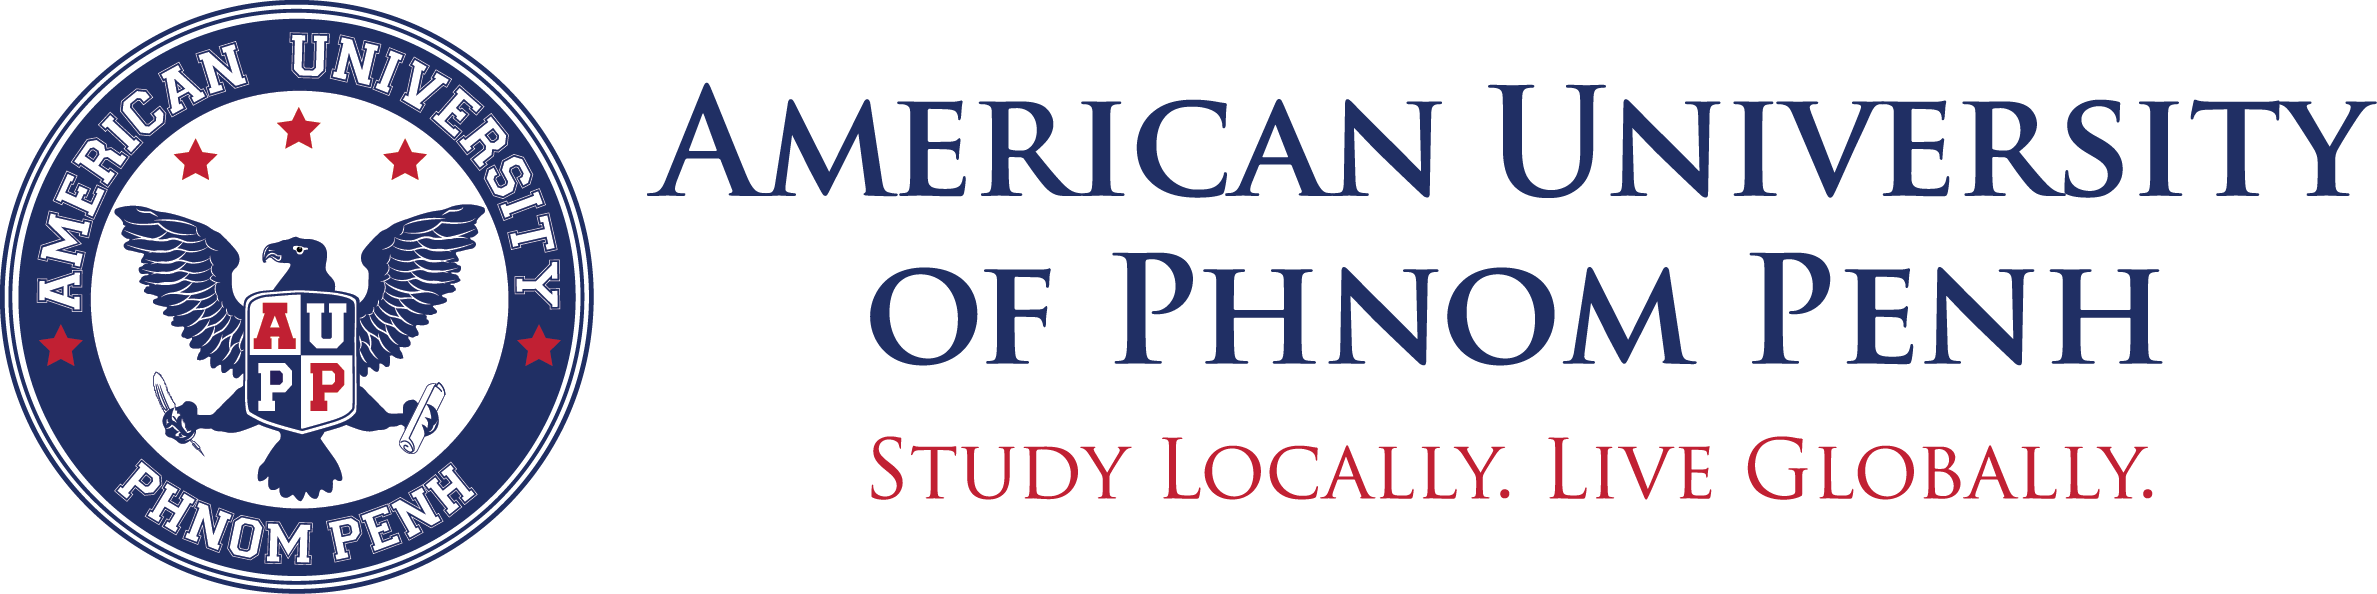

### School of Digital Technologies  
#### ITM-360: Artificial Intelligence
#### Lab-Practice: Softmax Regression Implementation from Scratch
 
**Lecturer:** Kuntha Pin (Ph.D Eng.)

</center>

---

### Contents
### 1. Introduction
### 2. The Model
### 3. The Cross-Entropy Loss
### 4. Training 
### 5. Prediction
### 6. Summary
---

# 1. Introduction

### Softmax Regression from scratch is a fundamental exercise in understanding how multi-class classification models transform raw data into probability distributions.   
  

In [1]:
# Import necessary libraries

import numpy as np
import struct
import matplotlib.pyplot as plt

- Additional resources: https://d2l.ai/chapter_linear-classification/softmax-regression-scratch.html

# 2. The Model

We now have everything that we need to implement the softmax regression model. As in our linear regression example, each instance will be represented by a fixed-length vector. Since the raw data here consists of 28 x 28 pixel images, we flatten each image, treating them as vectors of length 784. 

In softmax regression, the number of outputs from our network should be equal to the number of classes. Since our dataset has 10 classes, our network has an output dimension of 10.

- Load MNIST From Raw IDX Files, it's really important when using NumPy library

In [2]:
def load_mnist_images(filename):
    """
    Load MNIST-style images from IDX file.
    """
    with open(filename, 'rb') as f:
        magic, num, rows, cols = struct.unpack(">IIII", f.read(16))
        images = np.frombuffer(f.read(), dtype=np.uint8)
        images = images.reshape(num, rows * cols)
        return images / 255.0  # normalize to [0,1]

def load_mnist_labels(filename):
    """
    Load MNIST-style labels from IDX file.
    """
    with open(filename, 'rb') as f:
        magic, num = struct.unpack(">II", f.read(8))
        labels = np.frombuffer(f.read(), dtype=np.uint8)
        return labels

In [3]:
X_train = load_mnist_images("Fashion-MNIST/train-images-idx3-ubyte")
y_train = load_mnist_labels("Fashion-MNIST/train-labels-idx1-ubyte")

X_test = load_mnist_images("Fashion-MNIST/t10k-images-idx3-ubyte")
y_test = load_mnist_labels("Fashion-MNIST/t10k-labels-idx1-ubyte")

print("Train:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (60000, 784) (60000,)
Test: (10000, 784) (10000,)


 - Computing the softmax requires three steps:   
(i) exponentiation of each term;   
(ii) a sum over each row to compute the normalization constant for each example;   
(iii) division of each row by its normalization constant, ensuring that the result sums to 1: 

$$
\mathrm{softmax}(\mathbf{X})_{ij}
=
\frac{
\exp\left(\mathbf{X}_{ij}\right)
}{
\sum_{k} \exp\left(\mathbf{X}_{ik}\right)
}.
$$

- Created the Softmax function

In [4]:
def softmax(X):
    X_shifted = X - np.max(X, axis=1, keepdims=True)
    exp_X = np.exp(X_shifted)
    return exp_X / np.sum(exp_X, axis=1, keepdims=True)

# 3. The Cross-Entropy Loss

Next, we implement the cross-entropy loss, one of the most common loss functions in deep learning. Since Softmax outputs probabilities, cross-entropy naturally measures how close those predictions are to the true distribution, making it ideal for classification tasks.

In [5]:
def cross_entropy(y_hat, y):
    N = y.shape[0]
    return -np.mean(np.log(y_hat[np.arange(N), y] + 1e-9))

In [6]:
def accuracy(y_hat, y):
    return np.mean(np.argmax(y_hat, axis=1) == y)

# 4. Training

Before traing, using One-Hot encoding is really important because:  
- True labels in the dataset are integers (0–9 for Fashion‑MNIST).
- The model output is a vector of probabilities from softmax:   $\hat{Y} = [0.05, 0.10, 0.80, \ldots, 0.01]$   
- To compute the gradient for learning, we need:    $error = \hat{Y} - Y$
- But Y must be in the same format as $\hat{Y}$   
    => That’s exactly what one-hot encoding does:   $y=2⇒Y=[0,0,1,0,0,0,0,0,0,0]$

In [7]:
def one_hot(y, num_classes):
    return np.eye(num_classes)[y]

In [8]:
def initialize_params(num_features, num_classes):
    W = np.random.normal(0, 0.01, (num_features, num_classes))
    b = np.zeros((1, num_classes))
    return W, b

In [9]:
def forward(X, W, b):
    return softmax(np.dot(X, W) + b)

def compute_gradients(X, y, W, b):
    N = X.shape[0]
    y_hat = forward(X, W, b)
    y_onehot = one_hot(y, W.shape[1])

    error = y_hat - y_onehot
    dW = np.dot(X.T, error) / N
    db = np.sum(error, axis=0, keepdims=True) / N

    return dW, db

- Training Part

In [10]:
def train(X_train, y_train, X_test, y_test,
          epochs=15, lr=0.1, batch_size=256):
    
    num_samples, num_features = X_train.shape
    num_classes = 10
    
    W, b = initialize_params(num_features, num_classes)
    
    train_losses, test_losses = [], []
    train_accs, test_accs = [], []
    
    for epoch in range(epochs):
        indices = np.random.permutation(num_samples)
        X_train = X_train[indices]
        y_train = y_train[indices]
        
        for i in range(0, num_samples, batch_size):
            X_batch = X_train[i:i+batch_size]
            y_batch = y_train[i:i+batch_size]
            
            dW, db = compute_gradients(X_batch, y_batch, W, b)
            W -= lr * dW
            b -= lr * db
        
        # Evaluate
        y_train_hat = forward(X_train, W, b)
        y_test_hat = forward(X_test, W, b)
        
        train_loss = cross_entropy(y_train_hat, y_train)
        test_loss = cross_entropy(y_test_hat, y_test)
        
        train_acc = accuracy(y_train_hat, y_train)
        test_acc = accuracy(y_test_hat, y_test)
        
        train_losses.append(train_loss)
        test_losses.append(test_loss)
        train_accs.append(train_acc)
        test_accs.append(test_acc)
        
        print(f"Epoch {epoch+1}: "
              f"Train Loss={train_loss:.4f}, "
              f"Train Acc={train_acc:.4f}, "
              f"Test Acc={test_acc:.4f}")
    
    return W, b, train_losses, test_losses, train_accs, test_accs

- By using 20 of epochs

In [11]:
W, b, train_losses, test_losses, train_accs, test_accs = train(
    X_train, y_train, X_test, y_test,
    epochs=20, lr=0.1, batch_size=256
)

Epoch 1: Train Loss=0.6110, Train Acc=0.8000, Test Acc=0.7889
Epoch 2: Train Loss=0.5509, Train Acc=0.8139, Test Acc=0.7989
Epoch 3: Train Loss=0.5088, Train Acc=0.8288, Test Acc=0.8163
Epoch 4: Train Loss=0.4903, Train Acc=0.8359, Test Acc=0.8236
Epoch 5: Train Loss=0.4796, Train Acc=0.8382, Test Acc=0.8245
Epoch 6: Train Loss=0.5320, Train Acc=0.8059, Test Acc=0.7869
Epoch 7: Train Loss=0.4644, Train Acc=0.8434, Test Acc=0.8279
Epoch 8: Train Loss=0.4728, Train Acc=0.8342, Test Acc=0.8152
Epoch 9: Train Loss=0.4672, Train Acc=0.8371, Test Acc=0.8166
Epoch 10: Train Loss=0.4406, Train Acc=0.8511, Test Acc=0.8333
Epoch 11: Train Loss=0.4499, Train Acc=0.8467, Test Acc=0.8305
Epoch 12: Train Loss=0.4379, Train Acc=0.8505, Test Acc=0.8325
Epoch 13: Train Loss=0.4433, Train Acc=0.8481, Test Acc=0.8331
Epoch 14: Train Loss=0.4282, Train Acc=0.8543, Test Acc=0.8376
Epoch 15: Train Loss=0.4466, Train Acc=0.8470, Test Acc=0.8338
Epoch 16: Train Loss=0.4292, Train Acc=0.8536, Test Acc=0.8375
E

- Then we plot the graph to visual the loss from train and test

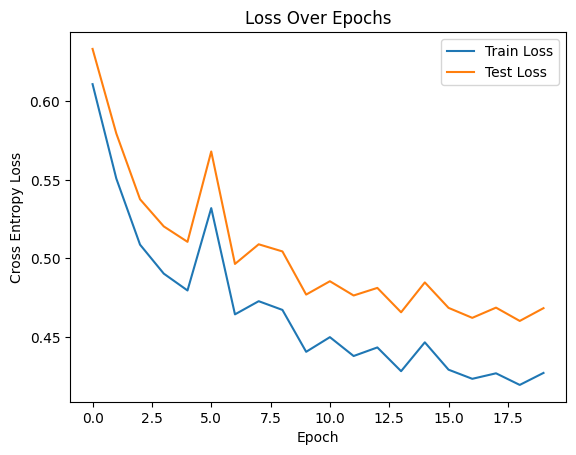

In [12]:
plt.figure()
plt.plot(train_losses, label="Train Loss")
plt.plot(test_losses, label="Test Loss")
plt.title("Loss Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")
plt.legend()
plt.show()

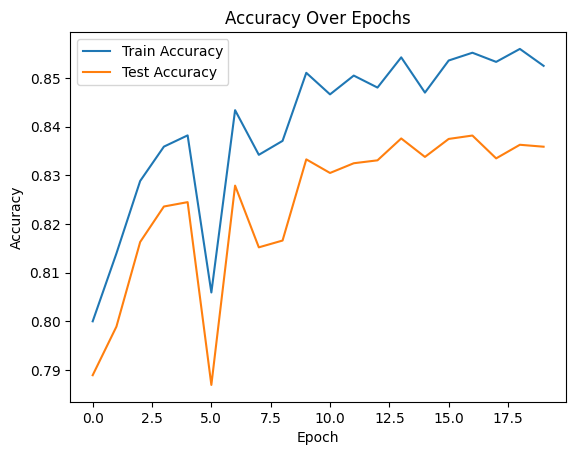

In [13]:
plt.figure()
plt.plot(train_accs, label="Train Accuracy")
plt.plot(test_accs, label="Test Accuracy")
plt.title("Accuracy Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# 5. Prediction

In [14]:
# Cell: Class labels
fashion_labels = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

In [15]:
# Cell: Prediction function

def predict(X, W, b):
    y_hat = forward(X, W, b)
    return np.argmax(y_hat, axis=1)

In [16]:
# Cell: Visualize predictions

def show_predictions(X, y_true, W, b, num_images=10):
    y_pred = predict(X[:num_images], W, b)
    
    plt.figure(figsize=(15, 3))
    
    for i in range(num_images):
        plt.subplot(1, num_images, i + 1)
        plt.imshow(X[i].reshape(28, 28), cmap="gray")
        
        true_label = fashion_labels[y_true[i]]
        pred_label = fashion_labels[y_pred[i]]
        
        color = "green" if y_true[i] == y_pred[i] else "red"
        plt.title(f"T:{true_label}\nP:{pred_label}", fontsize=8, color=color)
        plt.axis("off")
    
    plt.show()

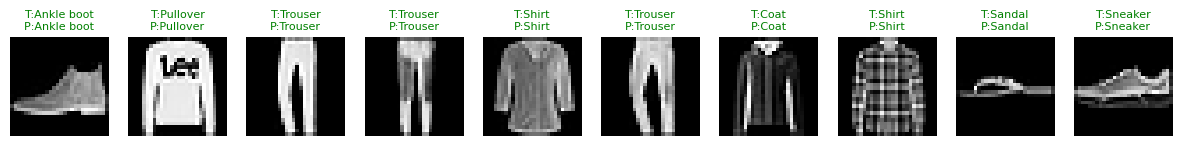

In [17]:
show_predictions(X_test, y_test, W, b, num_images=10)

In [18]:
y_test_pred = predict(X_test, W, b)
test_accuracy = np.mean(y_test_pred == y_test)
print("Final Test Accuracy:", test_accuracy)

Final Test Accuracy: 0.8359


### Summary

By now, we have built a solid foundation in linear regression and classification. These core techniques are essential in machine learning. Next, we will explore how deep learning frameworks allow us to implement these models more efficiently and apply them to real-world problems.

--- 

## Student Tasks

General Instructions
* Question 1: Continue working from the original code. Do not modify or delete the original code. Record the necessary information from the original model and your modified version so that you can compare the results.
  
* Question 2: You may search online resources or documents to learn more about the concepts. Please provide a reference for the information you use.
  
* **Important: Answer each question in the designated code or answer block. The original code is provided for you, and answer blocks have been prepared for your work. Please do not modify the original code. Only add or write your code in the appropriate answer blocks.


--- 

## Question 1. Model Performance Improvement

In [27]:
# Record the original model and results without changing them.
original_W = W.copy()
original_b = b.copy()

original_history = {
    "train_loss": train_losses.copy(),
    "test_loss": test_losses.copy(),
    "train_acc": train_accs.copy(),
    "test_acc": test_accs.copy()
}

def train_improved(X_train, y_train, X_test, y_test,
                   epochs=40, lr=0.001, batch_size=128, seed=42,
                   beta1=0.9, beta2=0.999, epsilon=1e-8):
    rng = np.random.default_rng(seed)

    # Separate parameters for the new model.
    W_new = rng.normal(0, 0.01, (X_train.shape[1], 10))
    b_new = np.zeros((1, 10))

    # Adam keeps first and second moments for both weights and biases.
    m_W, v_W = np.zeros_like(W_new), np.zeros_like(W_new)
    m_b, v_b = np.zeros_like(b_new), np.zeros_like(b_new)
    step = 0

    history = {
        "train_loss": [], "test_loss": [],
        "train_acc": [], "test_acc": []
    }

    for epoch in range(epochs):
        indices = rng.permutation(len(X_train))

        for start in range(0, len(indices), batch_size):
            batch = indices[start:start + batch_size]

            dW, db = compute_gradients(
                X_train[batch], y_train[batch], W_new, b_new
            )

            # Increment once per mini-batch, retaining moments across epochs.
            step += 1
            m_W = beta1 * m_W + (1 - beta1) * dW
            v_W = beta2 * v_W + (1 - beta2) * dW ** 2
            m_b = beta1 * m_b + (1 - beta1) * db
            v_b = beta2 * v_b + (1 - beta2) * db ** 2

            # Correct the initial bias from zero-initialized moments.
            m_W_hat = m_W / (1 - beta1 ** step)
            v_W_hat = v_W / (1 - beta2 ** step)
            m_b_hat = m_b / (1 - beta1 ** step)
            v_b_hat = v_b / (1 - beta2 ** step)

            W_new -= lr * m_W_hat / (np.sqrt(v_W_hat) + epsilon)
            b_new -= lr * m_b_hat / (np.sqrt(v_b_hat) + epsilon)

        for split, X, y in [
            ("train", X_train, y_train),
            ("test", X_test, y_test)
        ]:
            probabilities = forward(X, W_new, b_new)
            history[split + "_loss"].append(
                cross_entropy(probabilities, y)
            )
            history[split + "_acc"].append(
                accuracy(probabilities, y)
            )

        print(
            f"Epoch {epoch + 1:2d} | Adam lr={lr:.4f} | "
            f"Train loss={history['train_loss'][-1]:.4f} | "
            f"Test loss={history['test_loss'][-1]:.4f} | "
            f"Train acc={history['train_acc'][-1]:.4f} | "
            f"Test acc={history['test_acc'][-1]:.4f}"
        )

    return W_new, b_new, history


W_improved, b_improved, improved_history = train_improved(
    X_train, y_train, X_test, y_test
)
original_accuracy = original_history["test_acc"][-1]
improved_accuracy = improved_history["test_acc"][-1]

print(f"\nOriginal test accuracy: {original_accuracy:.2%}")
print(f"Adam test accuracy: {improved_accuracy:.2%}")
print(
    f"Change: {(improved_accuracy - original_accuracy) * 100:+.2f} "
    "percentage points"
)


Epoch  1 | Adam lr=0.0010 | Train loss=0.5416 | Test loss=0.5674 | Train acc=0.8200 | Test acc=0.8089
Epoch  2 | Adam lr=0.0010 | Train loss=0.4798 | Test loss=0.5103 | Train acc=0.8410 | Test acc=0.8297
Epoch  3 | Adam lr=0.0010 | Train loss=0.4543 | Test loss=0.4887 | Train acc=0.8478 | Test acc=0.8345
Epoch  4 | Adam lr=0.0010 | Train loss=0.4372 | Test loss=0.4750 | Train acc=0.8511 | Test acc=0.8365
Epoch  5 | Adam lr=0.0010 | Train loss=0.4257 | Test loss=0.4643 | Train acc=0.8556 | Test acc=0.8392
Epoch  6 | Adam lr=0.0010 | Train loss=0.4229 | Test loss=0.4664 | Train acc=0.8544 | Test acc=0.8355
Epoch  7 | Adam lr=0.0010 | Train loss=0.4128 | Test loss=0.4576 | Train acc=0.8595 | Test acc=0.8407
Epoch  8 | Adam lr=0.0010 | Train loss=0.4093 | Test loss=0.4551 | Train acc=0.8599 | Test acc=0.8424
Epoch  9 | Adam lr=0.0010 | Train loss=0.4005 | Test loss=0.4479 | Train acc=0.8629 | Test acc=0.8432
Epoch 10 | Adam lr=0.0010 | Train loss=0.3960 | Test loss=0.4454 | Train acc=0.864

Answer the following questions:

- What did you change?
   - -> Answer: I changed the optimizer from mini-batch SGD to Adam, using lr = 0.001, beta1 = 0.9, beta2 = 0.999, and epsilon = 1e-8. I increased training from 20 to 40 epochs and reduced the batch size from 256 to 128. I kept the softmax model and preprocessing unchanged. Seed 42 makes the Adam initialization and batch order reproducible.
- Why do you think your change could improve the model? (Hypothesis)
   - -> Answer: Adam uses moving averages of gradients and squared gradients to adapt each parameter's update size. Together with more epochs and more updates per epoch from the smaller batches, this may help the model converge to a better solution and improve accuracy.
- Plot the training and test performance over the epochs.
   - -> Answer: The Question 2 code plots training and test cross-entropy loss and accuracy for both the original model and the Adam model.
- Compare the original test accuracy with the improved test accuracy.
   - -> Answer: In the saved run, the original test accuracy was 83.59% and Adam's final test accuracy was 84.80%, an improvement of 1.21 percentage points.
- Did your hypothesis match the result? Explain briefly.
   - -> Answer: Yes, the modified training setup achieved higher test accuracy in this run. I changed the optimizer, learning rate, epoch count, and batch size together, so other modification contribute to this increase not just the optimizer.

Reference: [Kingma and Ba: Adam: A Method for Stochastic Optimization](https://arxiv.org/abs/1412.6980)


## Question 2. Identify the Training Behavior

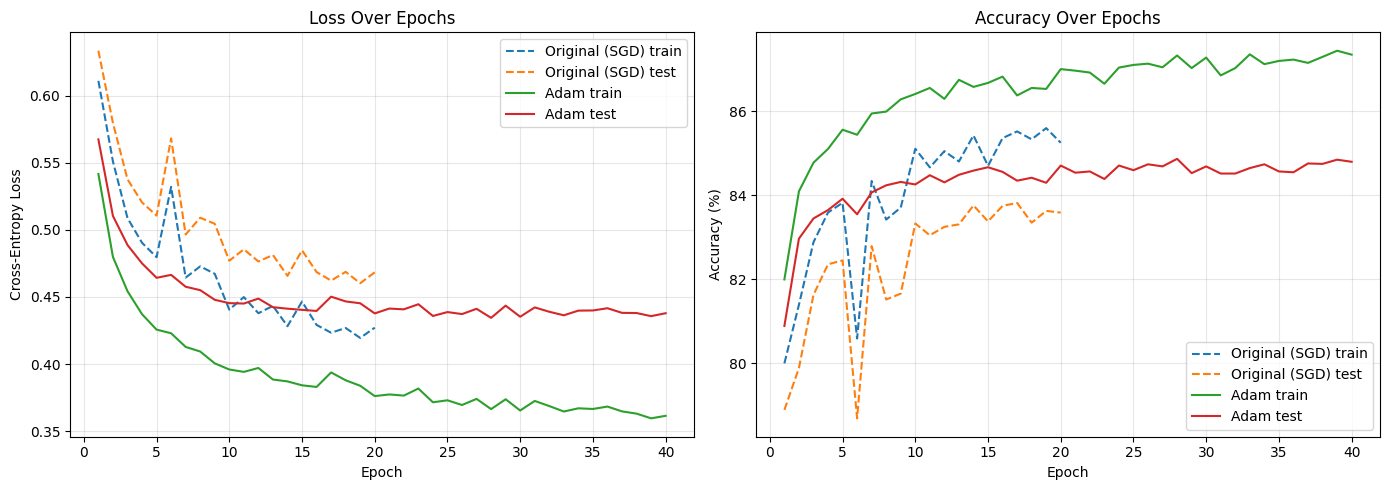

In [29]:
# You may write code to plot Loss Over Epochs and Accuracy Over Epochs graphs
# Plot the original and Adam models from Question 1.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, history, style in [
    ("Original (SGD)", original_history, "--"),
    ("Adam", improved_history, "-")
]:
    epoch_numbers = np.arange(1, len(history["train_loss"]) + 1)

    for split in ["train", "test"]:
        axes[0].plot(
            epoch_numbers, history[split + "_loss"],
            linestyle=style, label=f"{name} {split}"
        )
        axes[1].plot(
            epoch_numbers, np.array(history[split + "_acc"]) * 100,
            linestyle=style, label=f"{name} {split}"
        )

for ax, title, ylabel in [
    (axes[0], "Loss Over Epochs", "Cross-Entropy Loss"),
    (axes[1], "Accuracy Over Epochs", "Accuracy (%)")
]:
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Answer the following questions: 
- How can you identify underfitting?
    - -> Answer: Underfitting occurs when the model performs poorly on both training and test data. Both losses remain relatively high, and both accuracies stay low, indicating that the model has not learned the patterns sufficiently.
- How can you identify overfitting?
   - -> Answer: Overfitting occurs when training performance continues improving while test performance worsens. Training loss decreases, but test loss starts increasing, and the gap between training and test accuracy grows.
- How can you identify reasonable fitting/generalization?
   - -> Answer: The model shows reasonable generalization when it performs well on both training and test data, with a relatively small performance gap. Both losses initially decrease and then stabilize. These distinctions follow the principles illustrated in [scikit-learn’s underfitting and overfitting example](https://scikit-learn.org/stable/auto_examples/model_selection/plot_underfitting_overfitting.html).
- Based on your results, what type of training behavior does your model show?
   - -> Answer: My result lean toward reasonable generalization with small signs of late-stage overfitting. Adam achieved 87.35% training accuracy and 84.80% test accuracy, a gap of 2.55 percentage points. Test loss reached 0.4344 at epoch 28, then fluctuated and finished at 0.4379, while training data continue to decrease overall. This suggested that later epochs mainly improved training performance with little additional benefit on the test data.
